# Лабораторная работа № 2
## Виртуальный датчик для контроля процесса обжига в печи

Хочу оценивать концентрацию каждую минуту по показаниям печи. По лабораторным пробам обучаю модели и проверяю их прогнозы.

## 1. Разведочный анализ данных

Смотрю, как меняются сигналы и как часто берут пробы. Каналы для расчёта динамики отбираю по раннему отрезку обучения.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from catboost import CatBoostRegressor
from IPython.display import display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from threadpoolctl import threadpool_limits

DATA_DIR = Path(".")
SEED = 42
DELAY = 12
DELAY_SCENARIOS = (0, 10, DELAY, 15)
LAGS = (0, 5, 15, 30, 60, 120, 240)
WINDOWS = (15, 60, 240)

plt.rcParams.update({
    "figure.dpi": 125,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
})
pd.options.display.float_format = "{:.4f}".format
pd.options.display.max_columns = None
pd.options.display.width = 160

def load_telemetry(split):
    raw = pd.read_csv(DATA_DIR / f"data_{split}.csv", parse_dates=["datetime"])
    raw = raw.set_index("datetime")
    # Несколько записей одной минуты свожу по каждому каналу отдельно.
    minute_data = raw.groupby(level=0).median().asfreq("min")
    summary = {
        "Строк в CSV": len(raw),
        "Лишних строк с повторной меткой": int(raw.index.duplicated().sum()),
        "Минут без строки": len(minute_data) - raw.index.nunique(),
        "Минут без показаний": int(minute_data.isna().all(axis=1).sum()),
    }
    return minute_data, summary

def load_lab(split):
    raw = pd.read_csv(DATA_DIR / f"target_{split}.csv", parse_dates=["Дата"])
    target = raw.set_index("Дата")["target"].sort_index()
    assert target.index.is_unique
    return target.dropna()

telemetry_train, train_summary = load_telemetry("train")
lab_train = load_lab("train")
display(pd.Series(train_summary, name="Обучающая телеметрия").to_frame())
print("Телеметрия:", telemetry_train.index.min(), "—", telemetry_train.index.max())
print("Пробы:", lab_train.index.min(), "—", lab_train.index.max())

Телеметрия: 2019-03-01 00:01:00 — 2019-10-07 19:58:00
Пробы: 2019-03-13 17:00:00 — 2019-10-07 21:00:00


,Обучающая телеметрия
Строк в CSV,319546
Лишних строк с повторной меткой,1548
Минут без строки,0
Минут без показаний,16


,"Пропуски, %",Медиана,IQR,"За границами 3 IQR, %"
telemetry_0,0.0053,0.7390,0.0807,20.2805
telemetry_1,0.0050,0.4861,0.0632,21.4179
telemetry_2,0.0050,0.2957,0.0188,19.3215
telemetry_3,0.0050,0.6395,0.0409,19.8505
telemetry_4,0.0418,0.9195,0.0003,21.3912
telemetry_5,0.0053,0.8295,0.1467,15.9377
telemetry_6,0.0050,0.7492,0.0584,21.2836
telemetry_7,0.0050,0.4108,0.1259,20.8710
telemetry_8,0.0050,0.4679,0.0281,0.0667
telemetry_9,0.0050,0.5818,0.3376,0.0000


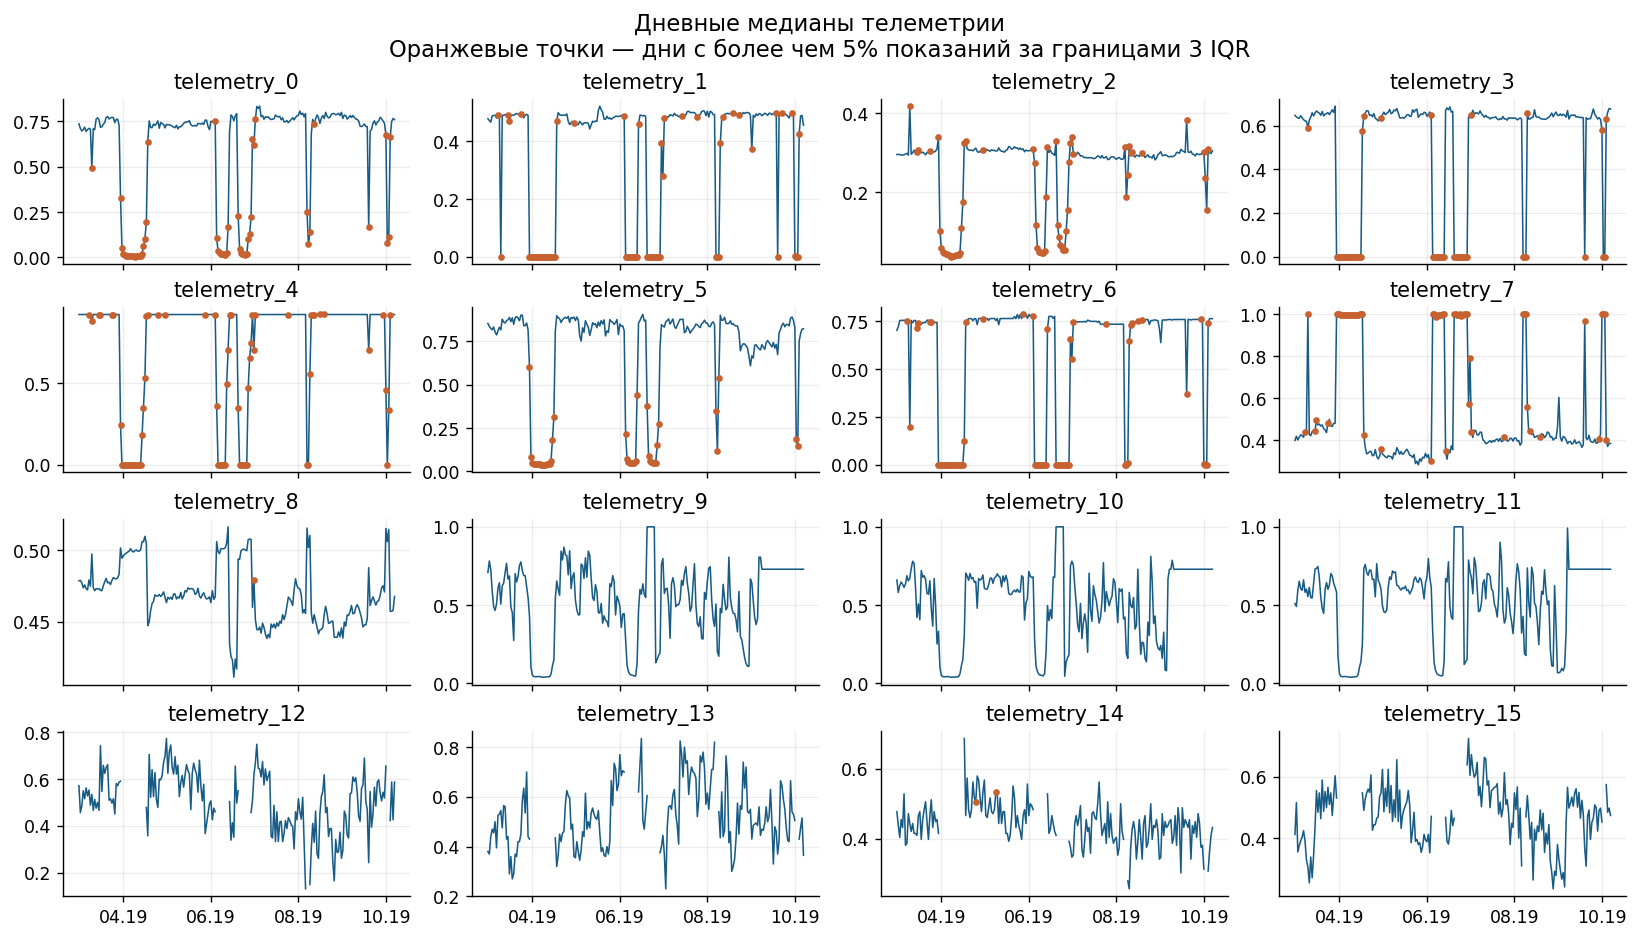

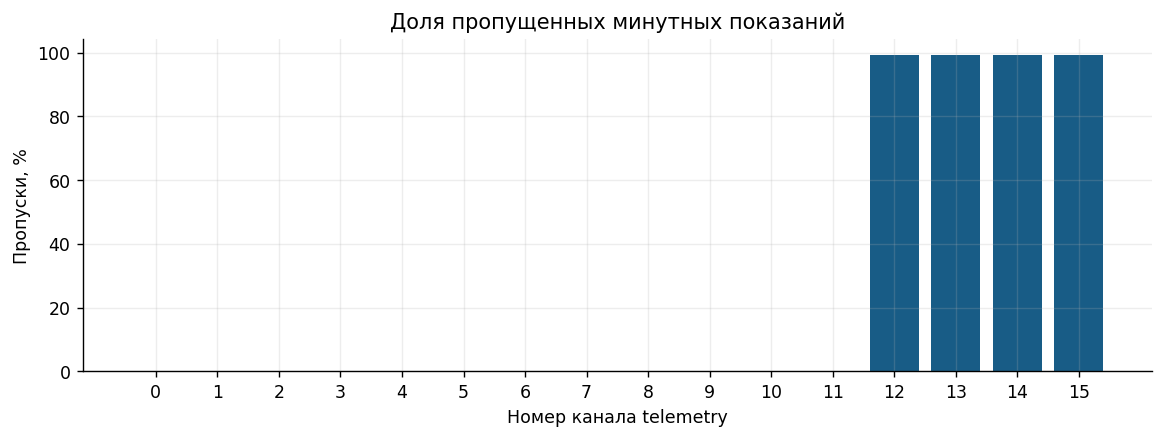

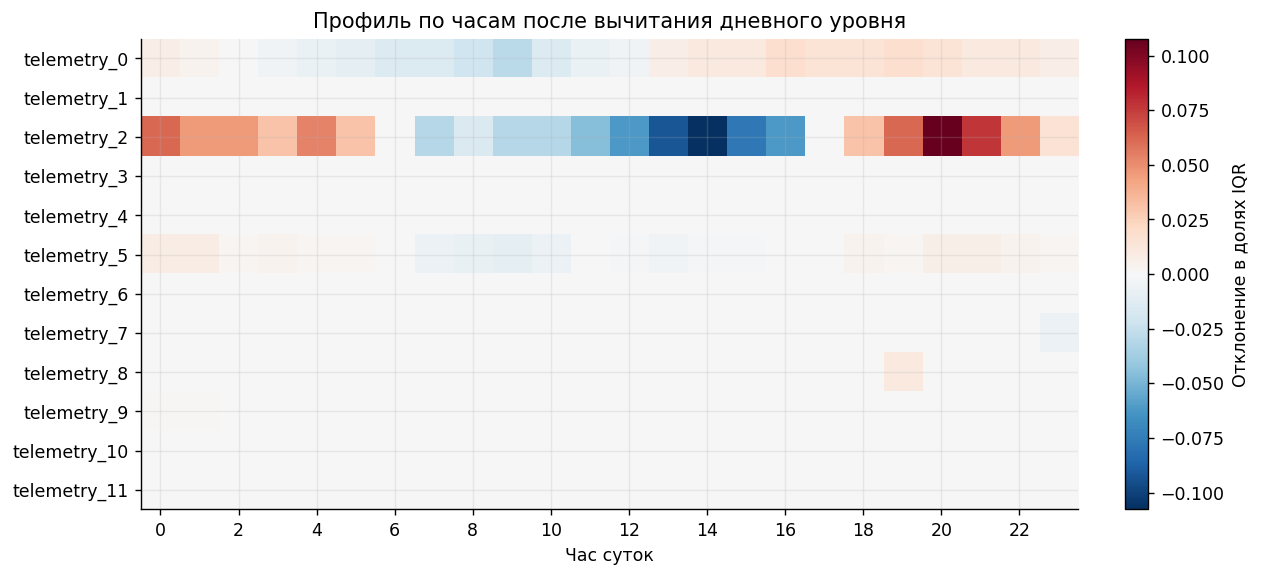

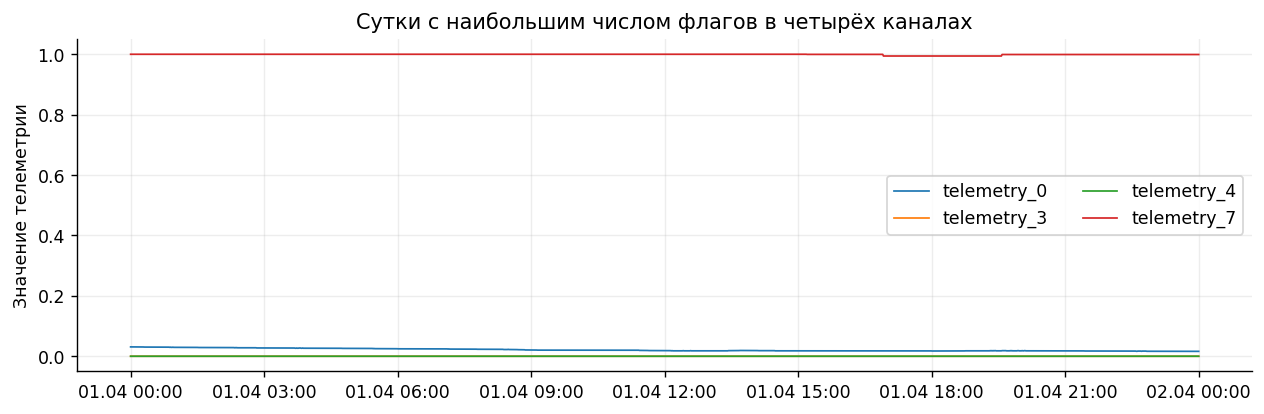

In [2]:
# У почти постоянного сигнала порог 3 IQR очень узкий.
quartiles = telemetry_train.quantile([0.25, 0.50, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
outside_iqr = (
    telemetry_train.lt(quartiles.loc[0.25] - 3 * iqr)
    | telemetry_train.gt(quartiles.loc[0.75] + 3 * iqr)
)
health = pd.DataFrame({
    "Пропуски, %": 100 * telemetry_train.isna().mean(),
    "Медиана": quartiles.loc[0.50],
    "IQR": iqr,
    "За границами 3 IQR, %": 100 * outside_iqr.sum() / telemetry_train.count(),
})
display(health)

daily = telemetry_train.resample("D").median()
daily_flags = outside_iqr.resample("D").sum().div(telemetry_train.resample("D").count())
fig, axes = plt.subplots(4, 4, figsize=(13, 7.4), sharex=True, layout="constrained")
for ax, channel in zip(axes.flat, daily.columns):
    ax.plot(daily.index, daily[channel], lw=0.9, color="#185c86")
    marked_days = daily[channel][daily_flags[channel] > 0.05]
    ax.scatter(marked_days.index, marked_days, s=8, color="#c76130", zorder=3)
    ax.set_title(channel)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
fig.suptitle("Дневные медианы телеметрии\nОранжевые точки — дни с более чем 5% показаний за границами 3 IQR",
             fontsize=13)
plt.show()

fig, ax = plt.subplots(figsize=(9.2, 3.4), layout="constrained")
ax.bar(range(len(health)), health["Пропуски, %"], color="#185c86")
ax.set(xticks=range(len(health)), xticklabels=range(len(health)),
       xlabel="Номер канала telemetry", ylabel="Пропуски, %",
       title="Доля пропущенных минутных показаний")
plt.show()

FIRST_VALIDATION = pd.Timestamp("2019-06-15")
early_missing = telemetry_train.loc[telemetry_train.index < FIRST_VALIDATION].isna().mean()
dense_channels = early_missing.index[early_missing < 0.5].tolist()

# Вычитаю дневную медиану, чтобы тренд не заслонял суточный профиль.
for_hourly = telemetry_train[dense_channels]
daily_level = for_hourly.groupby(for_hourly.index.normalize()).transform("median")
hour_profile = ((for_hourly - daily_level) / iqr[dense_channels].replace(0, np.nan))
hour_profile = hour_profile.groupby(hour_profile.index.hour).median().T
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
limit = max(np.nanmax(np.abs(hour_profile.to_numpy())), 0.01)
image = ax.imshow(hour_profile, aspect="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set(yticks=range(len(hour_profile)), yticklabels=hour_profile.index,
       xticks=range(0, 24, 2), xlabel="Час суток",
       title="Профиль по часам после вычитания дневного уровня")
fig.colorbar(image, ax=ax, label="Отклонение в долях IQR")
plt.show()

focus_channels = ["telemetry_0", "telemetry_3", "telemetry_4", "telemetry_7"]
focus_start = outside_iqr[focus_channels].resample("D").sum().sum(axis=1).idxmax()
focus = telemetry_train[focus_channels].loc[
    focus_start:focus_start + pd.Timedelta(days=1)
]
fig, ax = plt.subplots(figsize=(10, 3.2), layout="constrained")
ax.plot(focus.index, focus, lw=1)
ax.legend(focus.columns, ncol=2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
ax.set(title="Сутки с наибольшим числом флагов в четырёх каналах",
       ylabel="Значение телеметрии")
plt.show()

Доля интервалов в 2 часа: 88.6%. Самая длинная пауза: 18.4 дня.
Записей ровно на границе часа: 1772. Нулевых значений: 1.


,Концентрация
count,1773.0000
mean,0.2543
std,0.0922
min,0.0000
25%,0.1753
50%,0.2474
75%,0.3144
max,0.7165


,Пар проб
Дата,
2.0000,1570
4.0000,184
1.0000,4
7.0000,2
1.5000,1


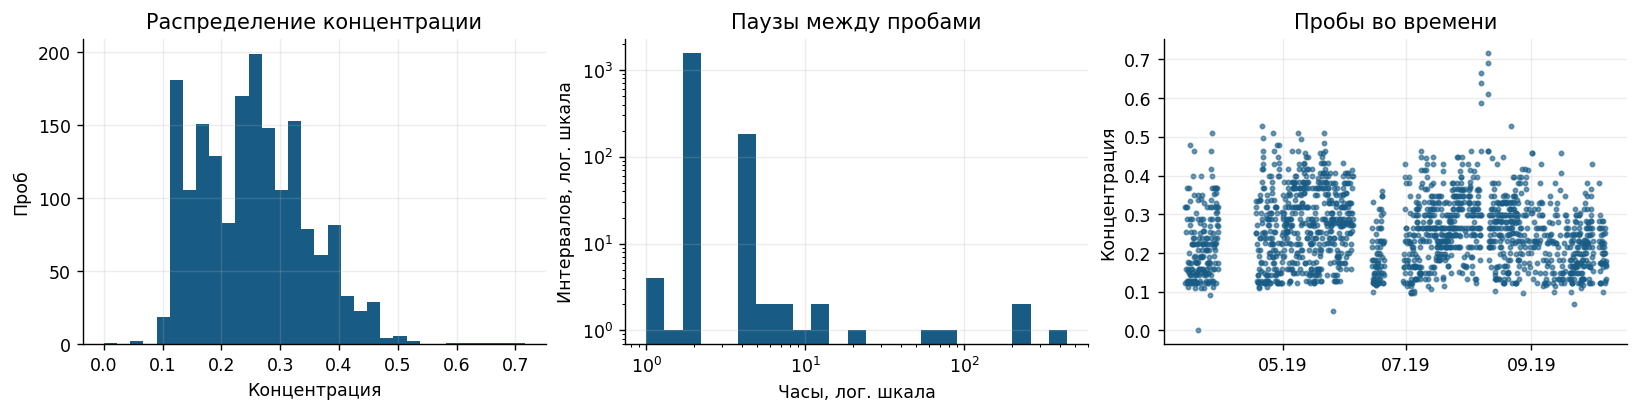

In [3]:
gap_hours = lab_train.index.to_series().diff().dt.total_seconds().div(3600).dropna()
target_summary = lab_train.describe()
display(target_summary.to_frame("Концентрация"))
display(gap_hours.value_counts().head(5).rename("Пар проб").to_frame())
print(f"Доля интервалов в 2 часа: {gap_hours.eq(2).mean():.1%}. "
      f"Самая длинная пауза: {gap_hours.max() / 24:.1f} дня.")
print(f"Записей ровно на границе часа: {(lab_train.index.minute == 0).sum()}. "
      f"Нулевых значений: {lab_train.eq(0).sum()}.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), layout="constrained")
axes[0].hist(lab_train, bins=32, color="#185c86")
axes[0].set(title="Распределение концентрации", xlabel="Концентрация", ylabel="Проб")
axes[1].hist(gap_hours, bins=np.geomspace(gap_hours.min(), gap_hours.max() * 1.01, 24),
             color="#185c86")
axes[1].set(xscale="log", yscale="log", title="Паузы между пробами",
            xlabel="Часы, лог. шкала", ylabel="Интервалов, лог. шкала")
axes[2].scatter(lab_train.index, lab_train, s=6, alpha=0.6, color="#185c86")
axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%m.%y"))
axes[2].set(title="Пробы во времени", ylabel="Концентрация")
plt.show()

### Синхронизация телеметрии и проб

У каждой пробы в журнале указано одно время. В основном расчёте считаю, что это время записи результата. Чтобы привязать пробу к моменту отбора, сдвигаю метку на 12 минут назад. Проверяю также сдвиги на 10 и 15 минут и вариант, в котором метка уже соответствует отбору.

Для пробы использую телеметрию до расчётного момента отбора включительно. Цель между пробами оставляю неизвестной. Одну пробу за пределами обучающей телеметрии исключаю.

Проб в границах телеметрии: 1772 из 1773.
Ключевые каналы: telemetry_0, telemetry_5, telemetry_7, telemetry_1, telemetry_8


,Сдвиг 0 мин,Сдвиг 10 мин,Сдвиг 12 мин,Сдвиг 15 мин
telemetry_0,0.3817,0.3795,0.3752,0.3716
telemetry_5,0.2394,0.2418,0.2440,0.2388
telemetry_7,0.2333,0.2509,0.2427,0.2425
telemetry_1,0.1800,0.1758,0.1735,0.1758
telemetry_8,0.1222,0.1209,0.1365,0.1249


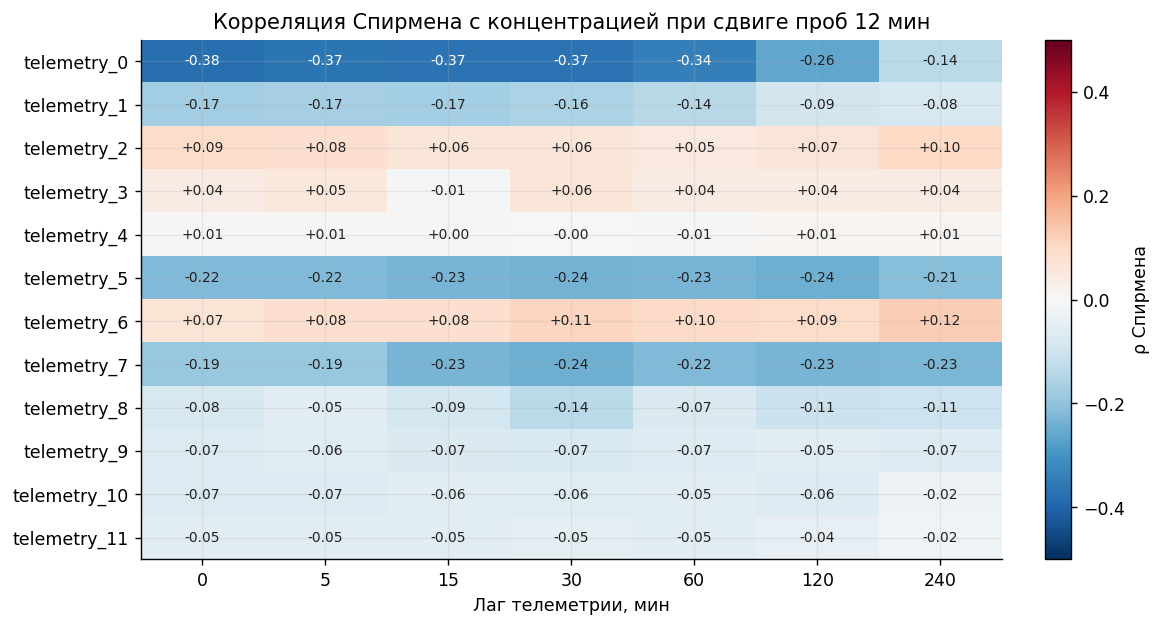

In [4]:
def sample_times(lab_times, delay):
    return lab_times - pd.Timedelta(minutes=delay)

# Сравниваю сдвиги на одном и том же наборе проб.
earliest_sample = sample_times(lab_train.index, max(DELAY_SCENARIOS))
latest_sample = sample_times(lab_train.index, min(DELAY_SCENARIOS))
inside_train = (
    (earliest_sample >= telemetry_train.index.min())
    & (latest_sample <= telemetry_train.index.max())
)
lab_train_covered = lab_train.loc[inside_train]
print(f"Проб в границах телеметрии: {len(lab_train_covered)} из {len(lab_train)}.")

early_lab = lab_train_covered.loc[lab_train_covered.index < FIRST_VALIDATION]
clean_train = telemetry_train[dense_channels].ffill(limit=15)

def lag_correlations(telemetry, lab, delay):
    correlations = {}
    for lag in LAGS:
        # Возвращаю метки проб для выравнивания с целью.
        readings = telemetry.reindex(sample_times(lab.index, delay + lag))
        readings.index = lab.index
        correlations[lag] = readings.corrwith(lab, method="spearman")
    return pd.DataFrame(correlations).T

delay_corr = {delay: lag_correlations(clean_train, early_lab, delay)
              for delay in DELAY_SCENARIOS}
main_corr = delay_corr[DELAY]
key_channels = main_corr.abs().max().nlargest(5).index.tolist()
print("Ключевые каналы:", ", ".join(key_channels))
display(pd.DataFrame({
    f"Сдвиг {delay} мин": corr.abs().max()[key_channels]
    for delay, corr in delay_corr.items()
}))

fig, ax = plt.subplots(figsize=(9.2, 4.9), layout="constrained")
image = ax.imshow(main_corr.T, aspect="auto", cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.set(yticks=range(len(dense_channels)), yticklabels=dense_channels,
       xticks=range(len(LAGS)), xticklabels=LAGS, xlabel="Лаг телеметрии, мин",
       title=f"Корреляция Спирмена с концентрацией при сдвиге проб {DELAY} мин")
for row, channel in enumerate(dense_channels):
    for col, lag in enumerate(LAGS):
        value = main_corr.loc[lag, channel]
        ax.text(col, row, f"{value:+.2f}", ha="center", va="center",
                fontsize=8, color="white" if abs(value) > 0.32 else "#222222")
fig.colorbar(image, ax=ax, label="ρ Спирмена")
plt.show()

**Вывод по EDA.** В обучении 16 минут совсем без показаний. У каналов 12–15 пропущено 99,34% значений, поэтому исключаю их. Последним показанием заполняю до 15 минут подряд, оставшиеся пропуски — медианой из обучения.

Отклонения за границами 3 IQR часто совпадают в нескольких каналах и держатся часами. Похоже, печь могла перейти в другой режим, поэтому оставляю эти участки. Суточные колебания лучше всего видны у `telemetry_2`.

Обычно пробы идут каждые два часа, самая длинная пауза — 18,4 дня. Половина замеров концентрации лежит между 0,175 и 0,314. У `telemetry_0` самая сильная связь с целью (ρ ≈ −0,38), при лаге 4 часа она слабее (ρ ≈ −0,14).

## 2. Инжиниринг признаков

Беру текущие значения 12 каналов. Для пяти каналов с наиболее сильной лаговой связью добавляю лаги до четырёх часов. Среднее, разброс, минимум и максимум считаю в окнах 15, 60 и 240 минут.

Скорость — разность показаний на концах интервала, делённая на его длину в минутах. Для часового темпа роста оставляю пропуск при исходном значении по модулю меньше 0,01, чтобы избежать резких скачков из-за деления. Исходные каналы сохраняю, чтобы было видно, какой датчик влияет на прогноз.

In [5]:
def build_features(telemetry, output_times):
    features = {}

    def add_block(block, suffix):
        for channel in block:
            features[f"{channel}__{suffix}"] = block[channel].reindex(output_times)

    add_block(telemetry, "now")
    key = telemetry[key_channels]
    for lag in LAGS[1:]:
        add_block(key.shift(lag), f"lag_{lag}m")

    for window in WINDOWS:
        # Окно включает текущую минуту. Нужно не меньше 75% показаний.
        rolling = key.rolling(window, min_periods=(3 * window + 3) // 4)
        for statistic in ("mean", "std", "min", "max"):
            add_block(getattr(rolling, statistic)(), f"{statistic}_{window}m")

    for lag in (15, 60):
        add_block(key.diff(lag) / lag, f"slope_{lag}m")
    previous = key.shift(60)
    growth = 100 * (key.div(previous.where(previous.abs() >= 0.01)) - 1)
    add_block(growth, "growth_60m")
    return pd.DataFrame(features, index=output_times)

all_train_times = pd.DatetimeIndex(
    sorted({time for delay in DELAY_SCENARIOS
            for time in sample_times(lab_train_covered.index, delay)})
)
train_features = build_features(clean_train, all_train_times)
level_cols = [col for col in train_features if col.endswith("__now")]
linear_dynamic_cols = level_cols + [
    f"{channel}__{kind}" for channel in key_channels[:3]
    for kind in ("mean_60m", "slope_60m")
]
short_dynamic_cols = level_cols + [
    f"{channel}__{kind}" for channel in key_channels
    for kind in ("mean_15m", "mean_60m", "std_60m", "slope_15m")
]
print(f"Признаков уровня: {len(level_cols)}. "
      f"С динамикой для МНК: {len(linear_dynamic_cols)}, "
      f"для деревьев: {len(short_dynamic_cols)} в коротком наборе "
      f"и {train_features.shape[1]} в полном.")

def training_rows(delay):
    y = lab_train_covered.copy()
    y.index = sample_times(y.index, delay)
    return train_features.loc[y.index], y

x_train, y_train = training_rows(DELAY)
display(x_train[[f"{key_channels[0]}__{name}" for name in
                 ("now", "lag_15m", "mean_60m", "slope_60m", "growth_60m")]].head())

Признаков уровня: 12. С динамикой для МНК: 18, для деревьев: 32 в коротком наборе и 117 в полном.


,telemetry_0__now,telemetry_0__lag_15m,telemetry_0__mean_60m,telemetry_0__slope_60m,telemetry_0__growth_60m
Дата,,,,,
2019-03-13 16:48:00,0.7873,0.7841,0.7847,0.0000,0.2579
2019-03-13 20:48:00,0.7824,0.7786,0.7759,0.0002,1.8840
2019-03-14 00:48:00,0.7873,0.7925,0.7875,-0.0001,-0.4026
2019-03-14 04:48:00,0.7494,0.7543,0.7655,-0.0004,-3.1414
2019-03-14 08:48:00,0.7679,0.7711,0.7720,-0.0002,-1.1914


**Вывод по признакам.** Текущий уровень описывает состояние печи, а скользящие средние и скорости помогают отличить устойчивый режим от резкого изменения. Для деревьев сравниваю 12 текущих уровней, короткий набор из 32 признаков и полный из 117.

## 3. Построение моделей

- **МНК-регрессия.** Даёт понятную линейную зависимость. Для динамики беру только часовые средние и скорости трёх каналов, чтобы ограничить число похожих признаков.
- **Случайный лес.** Учитывает пороги и сочетания показаний разных каналов. Ограничиваю глубину деревьев и задаю минимум проб в листе, чтобы одна проба меньше влияла на прогноз.
- **CatBoost.** Последовательно исправляет ошибки предыдущих деревьев. Для небольшого числа проб беру неглубокие деревья и малый шаг обучения.

Классификаторы рассчитаны на категории, а концентрация непрерывна. Обычная ARIMA на одной цели требует регулярных замеров. Глубокая LSTM при таком количестве проб легко переобучится.

Обучаюсь на прошлом, проверяю на трёх следующих отрезках. Оставляю 15 минут перед каждым отрезком проверки, чтобы к его началу результаты обучающих проб уже были известны. Выбираю модели с историей по среднему MAE. Для сравнения беру медиану и лучший вариант на текущих уровнях.

In [6]:
def with_imputer(estimator):
    # В каждом проходе медианы считаются только по обучающим строкам.
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), estimator)

prototypes = {
    "МНК": with_imputer(LinearRegression()),
    "Случайный лес": with_imputer(RandomForestRegressor(
        n_estimators=220, max_depth=9, min_samples_leaf=8,
        max_features=0.75, random_state=SEED, n_jobs=1,
    )),
    "CatBoost": with_imputer(CatBoostRegressor(
        iterations=350, depth=5, learning_rate=0.04, l2_leaf_reg=6,
        loss_function="RMSE", random_seed=SEED, verbose=False,
        allow_writing_files=False, thread_count=1,
    )),
    "Медиана": with_imputer(DummyRegressor(strategy="median")),
}
level_name = "Уровни"
dynamic_name = "Уровни и динамика"
short_name = "Короткая история"
specs = {
    (model_name, level_name): level_cols for model_name in prototypes
}
specs["МНК", dynamic_name] = linear_dynamic_cols
for model_name in ("Случайный лес", "CatBoost"):
    specs[model_name, short_name] = short_dynamic_cols
    specs[model_name, dynamic_name] = list(x_train.columns)

fold_edges = pd.date_range(FIRST_VALIDATION, lab_train_covered.index.max() + pd.Timedelta("1min"),
                           periods=4).floor("min")

def validate(model_name, columns, features, labels):
    results = {}
    for fold, (start, end) in enumerate(zip(fold_edges[:-1], fold_edges[1:]), start=1):
        known = labels.index <= start - pd.Timedelta(minutes=15)
        after = (labels.index >= start) & (labels.index < end)
        model = clone(prototypes[model_name])
        model.fit(features.loc[known, columns], labels.loc[known])
        predicted = model.predict(features.loc[after, columns])
        results[f"MAE {fold}"] = mean_absolute_error(labels.loc[after], predicted)
    return results

fold_info = []
for start, end in zip(fold_edges[:-1], fold_edges[1:]):
    fold_info.append({
        "Начало": start, "Конец (исключая)": end,
        "Проб в обучении": (y_train.index <= start - pd.Timedelta(minutes=15)).sum(),
        "Проб в проверке": ((y_train.index >= start) & (y_train.index < end)).sum(),
    })
display(pd.DataFrame(fold_info))

with threadpool_limits(limits=1):
    validation = pd.DataFrame([
        {"Модель": model_name, "Признаки": feature_name,
         **validate(model_name, columns, x_train, y_train)}
        for (model_name, feature_name), columns in specs.items()
    ])
validation["Средний MAE"] = validation[["MAE 1", "MAE 2", "MAE 3"]].mean(axis=1)
validation = validation.sort_values("Средний MAE").reset_index(drop=True)
display(validation)

selected = validation.loc[validation["Признаки"].ne(level_name)].drop_duplicates("Модель")
selected_specs = list(selected[["Модель", "Признаки"]].itertuples(index=False, name=None))
winner, winner_features = selected_specs[0]
winner_cols = specs[winner, winner_features]
level_control = validation.loc[
    validation["Признаки"].eq(level_name) & validation["Модель"].ne("Медиана"), "Модель"
].iloc[0]

sensitivity = []
with threadpool_limits(limits=1):
    for delay in DELAY_SCENARIOS:
        x_scenario, y_scenario = training_rows(delay)
        scores = validate(winner, winner_cols, x_scenario, y_scenario)
        sensitivity.append({"Сдвиг, мин": delay, **scores, "Средний MAE": np.mean(list(scores.values()))})
display(pd.DataFrame(sensitivity))

,Начало,Конец (исключая),Проб в обучении,Проб в проверке
0,2019-06-15 00:00:00,2019-07-23 06:20:00,771,328
1,2019-07-23 06:20:00,2019-08-30 12:40:00,1099,373
2,2019-08-30 12:40:00,2019-10-07 19:01:00,1472,300


,Модель,Признаки,MAE 1,MAE 2,MAE 3,Средний MAE
0,Случайный лес,Уровни,0.0678,0.0761,0.0651,0.0697
1,Случайный лес,Короткая история,0.0665,0.0739,0.0692,0.0699
2,CatBoost,Уровни,0.0705,0.0771,0.0658,0.0712
3,CatBoost,Уровни и динамика,0.0661,0.0751,0.0735,0.0715
4,Медиана,Уровни,0.0683,0.0757,0.0718,0.0719
5,Случайный лес,Уровни и динамика,0.0650,0.0750,0.0764,0.0721
6,CatBoost,Короткая история,0.0708,0.0749,0.0715,0.0724
7,МНК,Уровни,0.0778,0.0721,0.0681,0.0727
8,МНК,Уровни и динамика,0.0769,0.0745,0.0693,0.0736


,"Сдвиг, мин",MAE 1,MAE 2,MAE 3,Средний MAE
0,0,0.0670,0.0741,0.0694,0.0702
1,10,0.0680,0.0745,0.0687,0.0704
2,12,0.0665,0.0739,0.0692,0.0699
3,15,0.0667,0.0741,0.0696,0.0701


**Вывод по моделям.** Среди вариантов с историей выигрывает лес с 32 признаками (MAE 0,0699). Лес на текущих уровнях показал близкий результат (0,0697).

При разных сдвигах метки MAE выбранного леса остаётся в пределах 0,0699–0,0704. Разница слишком мала, чтобы по ней судить о времени отбора.

## 4. Оценка качества

MAE и RMSE считаю в шкале CSV. MAPE — среднее отношение модуля ошибки к модулю ненулевого замера, WAPE — сумма модулей ошибок, делённая на сумму модулей замеров.

MDA показывает долю угаданных подъёмов и спадов между пробами с интервалом до четырёх часов. Нулевые изменения факта пропускаю, нулевой прогноз изменения считаю промахом. Сбалансированная MDA усредняет точность по двум направлениям.

In [7]:
telemetry_test, test_summary = load_telemetry("test_small")
lab_test = load_lab("test_small")
assert telemetry_train.index.max() < telemetry_test.index.min()
y_test = lab_test.copy()
y_test.index = sample_times(y_test.index, DELAY)
y_test = y_test.loc[y_test.index.isin(telemetry_test.index)]
assert y_train.index.max() < y_test.index.min()

# 240 минут для признаков и ещё 15 для заполнения коротких разрывов.
context = pd.concat([
    telemetry_train[dense_channels].tail(max(WINDOWS) + 15),
    telemetry_test[dense_channels],
]).asfreq("min").ffill(limit=15)
with threadpool_limits(limits=1):
    start = perf_counter()
    test_minute_features = build_features(context, telemetry_test.index)
    feature_seconds = perf_counter() - start

display(pd.Series(test_summary, name="Тестовая телеметрия").to_frame())
print(f"Проб в тесте: {len(y_test)} из {len(lab_test)}. "
      f"Средняя концентрация: обучение {y_train.mean():.4f}, тест {y_test.mean():.4f}.")

def direction_pairs(actual, prediction):
    gap = actual.index.to_series().diff().dt.total_seconds().div(3600)
    step = actual.diff()
    valid = gap.between(0, 4, inclusive="right") & step.notna() & step.ne(0)
    return np.sign(step.loc[valid]), np.sign(prediction.diff().loc[valid])

def score_test(actual, prediction):
    errors = (actual - prediction).abs()
    nonzero = actual.ne(0)
    actual_sign, predicted_sign = direction_pairs(actual, prediction)
    hits = actual_sign.eq(predicted_sign)
    per_direction = hits.groupby(actual_sign).mean()
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "MAPE, %": 100 * (errors.loc[nonzero] / actual.loc[nonzero].abs()).mean(),
        "WAPE, %": 100 * errors.sum() / actual.abs().sum(),
        "MDA, %": 100 * hits.mean(),
        "Сбал. MDA, %": 100 * per_direction.mean(),
    }

pred_minute = pd.DataFrame(index=telemetry_test.index)
fitted = {}
metrics = []
timings = []
controls = [(level_control, level_name), ("Медиана", level_name)]
with threadpool_limits(limits=1):
    for model_name, feature_name in selected_specs + controls:
        columns = specs[model_name, feature_name]
        label = f"{model_name} без истории" if (model_name, feature_name) == controls[0] else model_name
        model = clone(prototypes[model_name])
        start = perf_counter()
        model.fit(x_train[columns], y_train)
        fit_seconds = perf_counter() - start

        x_minute = test_minute_features[columns]
        times_ms = []
        for _ in range(3):
            start = perf_counter()
            values = model.predict(x_minute)
            times_ms.append(1000 * (perf_counter() - start))
        pred_minute[label] = values
        fitted[label] = model
        metrics.append({
            "Модель": label, "Признаки": feature_name,
            **score_test(y_test, pred_minute.loc[y_test.index, label]),
        })
        timings.append({
            "Модель": label, "Обучение, с": fit_seconds,
            "Весь минутный тест, мс": np.median(times_ms),
            "На минуту в пакете, мкс": 1000 * np.median(times_ms) / len(x_minute),
        })

assert np.isfinite(pred_minute.to_numpy()).all()
pred_at_lab = pred_minute.loc[y_test.index]
test_metrics = pd.DataFrame(metrics).set_index("Модель")
test_timings = pd.DataFrame(timings).set_index("Модель")
display(test_metrics)
actual_sign, _ = direction_pairs(y_test, pred_at_lab[winner])
print(f"Пар для оценки направления: {len(actual_sign)}. "
      f"Подъёмов: {actual_sign.eq(1).sum()}, спадов: {actual_sign.eq(-1).sum()}. "
      f"Проб для MAPE: {y_test.ne(0).sum()}.")
display(test_timings)
print(f"Минутных прогнозов на модель: {len(pred_minute):,}. "
      "Замер включает заполнение пропусков и вызов predict. "
      f"Расчёт признаков для минутного теста: {feature_seconds:.2f} с.")

Проб в тесте: 318 из 318. Средняя концентрация: обучение 0.2543, тест 0.2097.
Пар для оценки направления: 299. Подъёмов: 144, спадов: 155. Проб для MAPE: 318.
Минутных прогнозов на модель: 39,747. Замер включает заполнение пропусков и вызов predict. Расчёт признаков для минутного теста: 0.06 с.


,Тестовая телеметрия
Строк в CSV,39943
Лишних строк с повторной меткой,196
Минут без строки,0
Минут без показаний,1


,Признаки,MAE,RMSE,"MAPE, %","WAPE, %","MDA, %","Сбал. MDA, %"
Модель,,,,,,,
Случайный лес,Короткая история,0.0627,0.0779,35.0491,29.9064,55.8528,55.8423
CatBoost,Уровни и динамика,0.0622,0.0765,35.1556,29.6392,55.8528,55.8669
МНК,Уровни и динамика,0.0656,0.0820,37.8949,31.2642,57.8595,57.8517
Случайный лес без истории,Уровни,0.0629,0.0784,34.5164,29.9987,53.1773,53.1138
Медиана,Уровни,0.0768,0.0888,45.7627,36.6391,0.0000,0.0000


,"Обучение, с","Весь минутный тест, мс","На минуту в пакете, мкс"
Модель,,,
Случайный лес,1.8275,83.8104,2.1086
CatBoost,2.4504,19.4904,0.4904
МНК,0.0026,2.2928,0.0577
Случайный лес без истории,0.6494,82.0654,2.0647
Медиана,0.0017,1.3902,0.0350


In [8]:
# Для обеих МНК-моделей беру одни и те же пробы.
criteria = []
for feature_name in (level_name, dynamic_name):
    columns = specs["МНК", feature_name]
    filled = SimpleImputer(strategy="median", keep_empty_features=True).fit_transform(x_train[columns])
    result = sm.OLS(y_train.to_numpy(), sm.add_constant(filled, has_constant="add")).fit()
    criteria.append({
        "Спецификация МНК": feature_name, "Проб": int(result.nobs),
        "Коэффициентов с константой": int(result.df_model + 1),
        "AIC": result.aic, "BIC": result.bic,
    })
display(pd.DataFrame(criteria).set_index("Спецификация МНК"))

,Проб,Коэффициентов с константой,AIC,BIC
Спецификация МНК,,,,
Уровни,1772,13,-3668.1706,-3596.9324
Уровни и динамика,1772,19,-3677.6566,-3573.5392


AIC и BIC считаю для двух вариантов МНК на одних пробах с гауссовым правдоподобием. Деревья сравниваю по ошибке и скорости. Время прогноза замеряю на всём минутном тесте в одном потоке. Подготовку признаков измеряю отдельно.

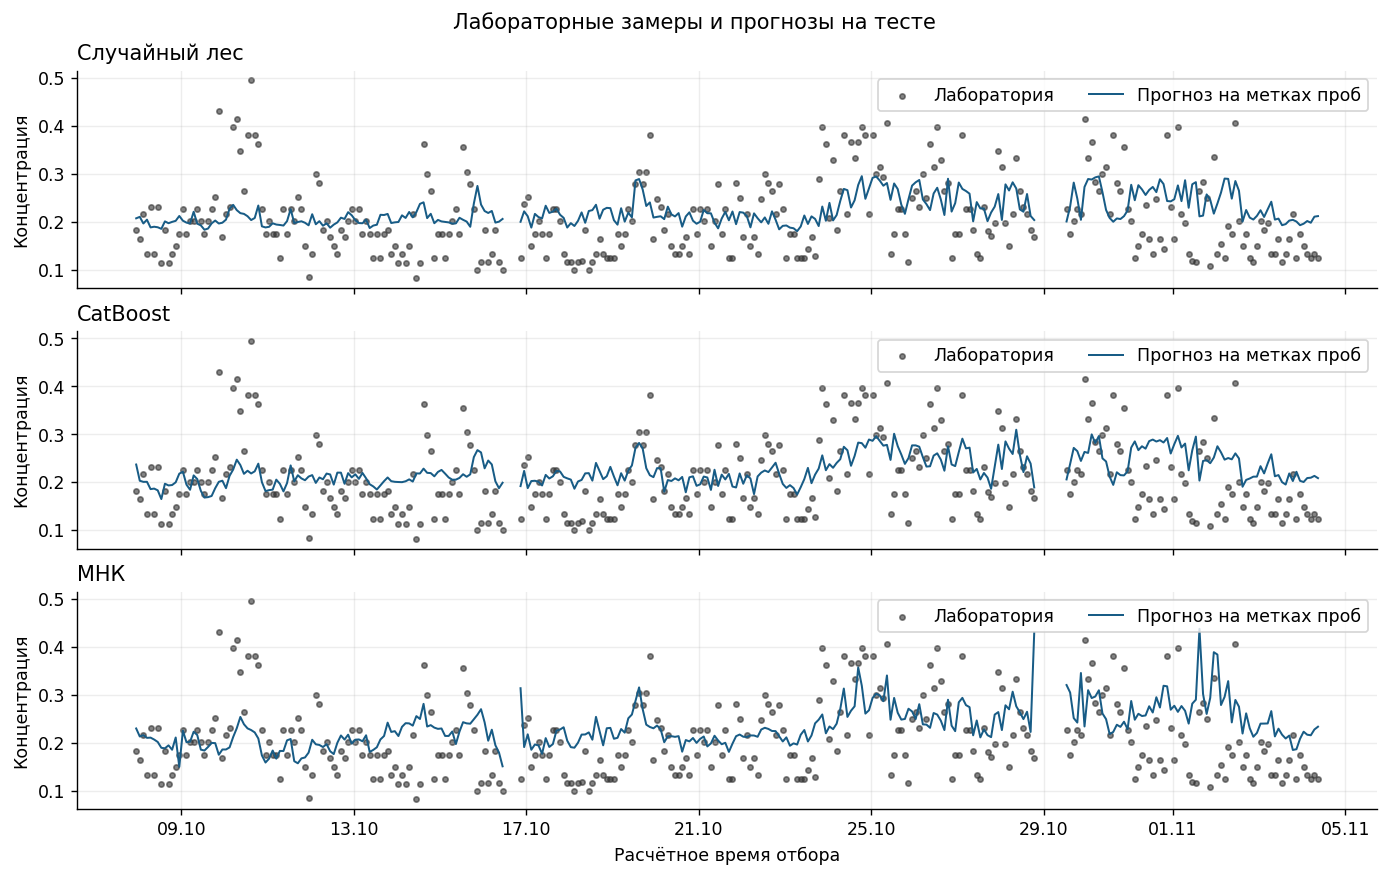

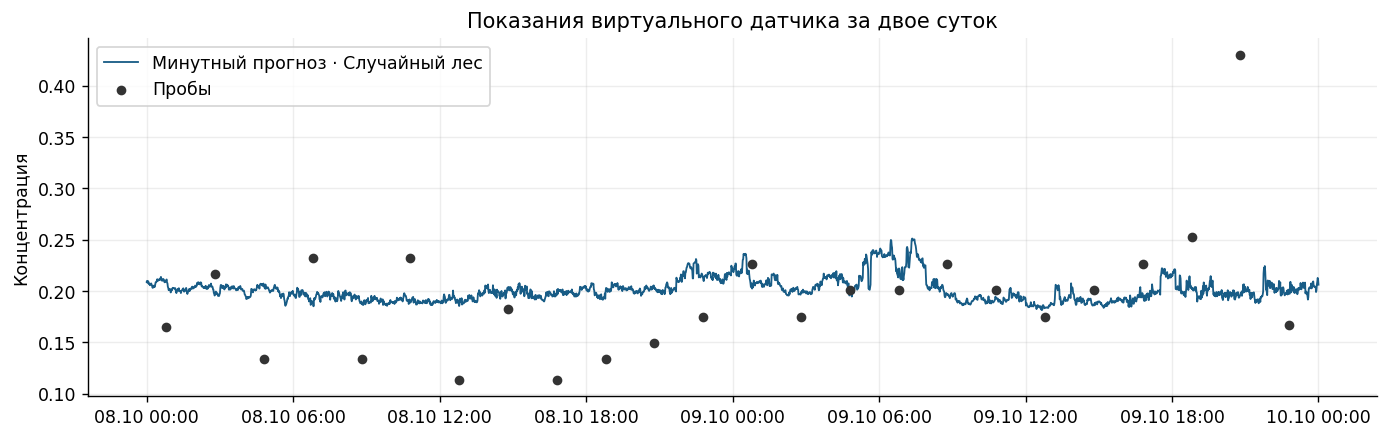

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.9), sharex=True, sharey=True,
                         layout="constrained")
for ax, (model_name, _) in zip(axes, selected_specs):
    ax.scatter(y_test.index, y_test, s=9, alpha=0.60, color="#333333", label="Лаборатория")
    # Линию разрываю, если в лабораторном ряду пауза больше 4 часов.
    groups = y_test.index.to_series().diff().gt(pd.Timedelta(hours=4)).cumsum()
    for i, (_, segment) in enumerate(pred_at_lab[model_name].groupby(groups)):
        ax.plot(segment.index, segment, lw=1.15, color="#185c86",
                label="Прогноз на метках проб" if i == 0 else None)
    ax.set_ylabel("Концентрация")
    ax.set_title(model_name, loc="left")
    ax.legend(loc="upper right", ncol=2)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
axes[-1].set_xlabel("Расчётное время отбора")
fig.suptitle("Лабораторные замеры и прогнозы на тесте")
plt.show()

start = y_test.index.min().floor("D") + pd.Timedelta(days=1)
end = start + pd.Timedelta(days=2)
minute_example = pred_minute[winner].loc[start:end]
lab_example = y_test.loc[start:end]
fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
ax.plot(minute_example, lw=1.05, color="#185c86", label=f"Минутный прогноз · {winner}")
ax.scatter(lab_example.index, lab_example, s=21, zorder=3, color="#333333", label="Пробы")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
ax.set(title="Показания виртуального датчика за двое суток", ylabel="Концентрация")
ax.legend()
plt.show()

На регулярном отрезке 144 проб: 16.10 20:48 — 28.10 18:48.


,Средний остаток,"Жарка–Бера, p","Льюнг–Бокс, p (12 ч)","Бройш–Паган, p"
Модель,,,,
Случайный лес,-0.0132,5.51e-08,3.65e-08,9.63e-04
CatBoost,-0.0161,1.93e-07,9.19e-08,2.39e-05
МНК,-0.0240,1.11e-05,4.85e-05,1.26e-10


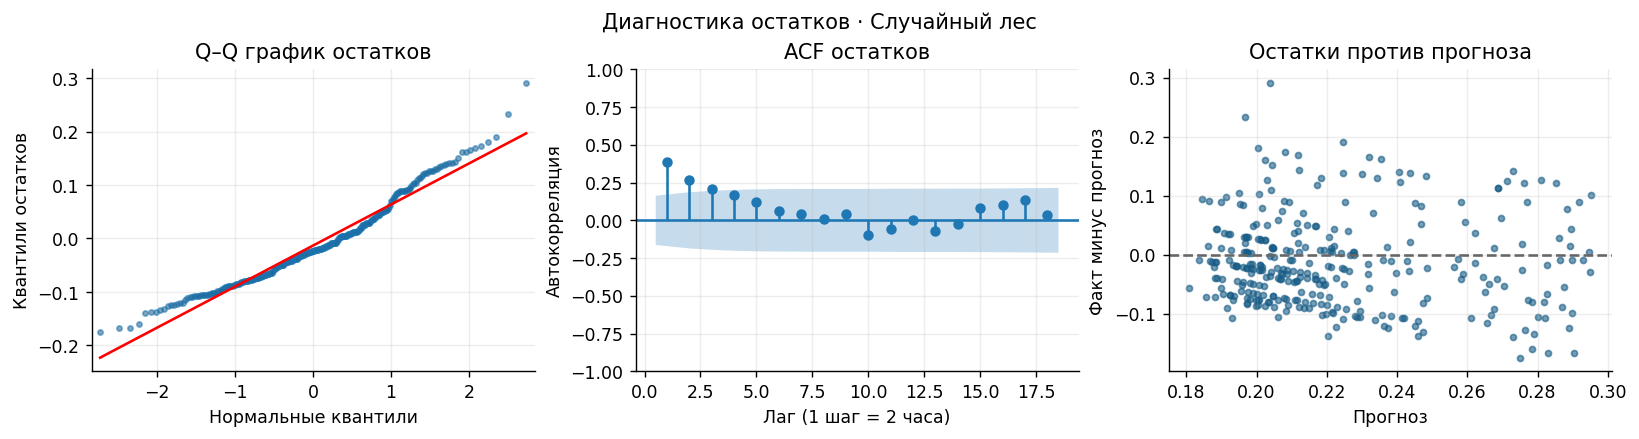

,Проб,Среднее,Ст. откл.
Случайный лес,,,
"(0.18, 0.201]",80,-0.0103,0.0625
"(0.201, 0.213]",79,-0.0022,0.0755
"(0.213, 0.238]",79,-0.0201,0.0770
"(0.238, 0.295]",80,-0.0200,0.0901


In [10]:
residuals = y_test - pred_at_lab[winner]
# Для ACF и Льюнга–Бокса нужен сплошной ряд с шагом 2 часа.
changes = residuals.index.to_series().diff().ne(pd.Timedelta(hours=2)).cumsum()
runs = [run for _, run in residuals.groupby(changes)]
regular = max(runs, key=len)

diagnostics = []
for model_name, _ in selected_specs:
    prediction = pred_at_lab[model_name]
    error = y_test - prediction
    jb_p = jarque_bera(error)[1]
    lb_p = acorr_ljungbox(error.loc[regular.index], lags=[6])["lb_pvalue"].iloc[0]
    bp_p = het_breuschpagan(error, sm.add_constant(prediction), robust=True)[1]
    diagnostics.append({
        "Модель": model_name, "Средний остаток": error.mean(),
        "Жарка–Бера, p": jb_p, "Льюнг–Бокс, p (12 ч)": lb_p,
        "Бройш–Паган, p": bp_p,
    })
tests = pd.DataFrame(diagnostics).set_index("Модель")
display(tests.style.format({
    "Средний остаток": "{:.4f}", "Жарка–Бера, p": "{:.2e}",
    "Льюнг–Бокс, p (12 ч)": "{:.2e}", "Бройш–Паган, p": "{:.2e}",
}))
print(f"На регулярном отрезке {len(regular)} проб: "
      f"{regular.index.min():%d.%m %H:%M} — {regular.index.max():%d.%m %H:%M}.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), layout="constrained")
sm.qqplot(residuals, line="s", ax=axes[0], markerfacecolor="#185c86", alpha=0.55, markersize=3)
axes[0].set(title="Q–Q график остатков", xlabel="Нормальные квантили", ylabel="Квантили остатков")
plot_acf(regular, lags=18, zero=False, ax=axes[1])
axes[1].set(title="ACF остатков", xlabel="Лаг (1 шаг = 2 часа)", ylabel="Автокорреляция")
axes[2].scatter(pred_at_lab[winner], residuals, s=12, alpha=0.60, color="#185c86")
axes[2].axhline(0, ls="--", color="#666666")
axes[2].set(title="Остатки против прогноза", xlabel="Прогноз", ylabel="Факт минус прогноз")
fig.suptitle(f"Диагностика остатков · {winner}")
plt.show()

residual_summary = residuals.groupby(
    pd.qcut(pred_at_lab[winner], 4, duplicates="drop"), observed=True
).agg(["size", "mean", "std"])
display(residual_summary.rename(columns={"size": "Проб", "mean": "Среднее", "std": "Ст. откл."}))

Жарка–Бера проверяет нормальность остатков, Льюнг–Бокс — автокорреляцию до 12 часов, Бройш–Паган — связь разброса ошибки с уровнем прогноза. Ошибки могут быть связаны во времени, поэтому смотрю и на p-value, и на графики.

Уникальные минутные показания в каналах 9–11:


,Прирост MAE,Ст. откл. по сдвигам
Канал,,
telemetry_0,0.0048,0.0017
telemetry_2,0.0005,0.0005
telemetry_6,0.0004,0.0003
telemetry_7,0.0002,0.0006
telemetry_5,0.0001,0.0003
telemetry_9,0.0000,0.0000
telemetry_10,0.0000,0.0000
telemetry_11,0.0000,0.0000
telemetry_4,-0.0000,0.0001


,Среднее |SHAP|
telemetry_0__mean_60m,0.0116
telemetry_9__now,0.0106
telemetry_11__now,0.0092
telemetry_10__now,0.0077
telemetry_2__now,0.0069
telemetry_0__mean_15m,0.0062
telemetry_6__now,0.0043
telemetry_0__now,0.0041
telemetry_1__std_60m,0.0037
telemetry_3__now,0.0030


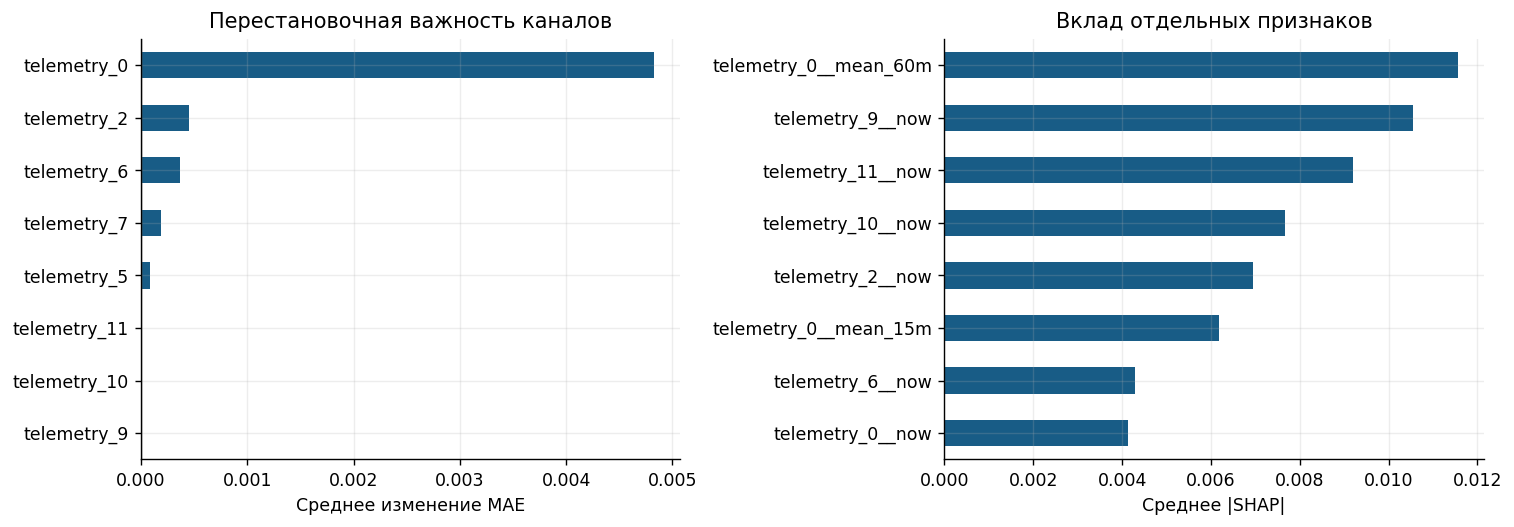

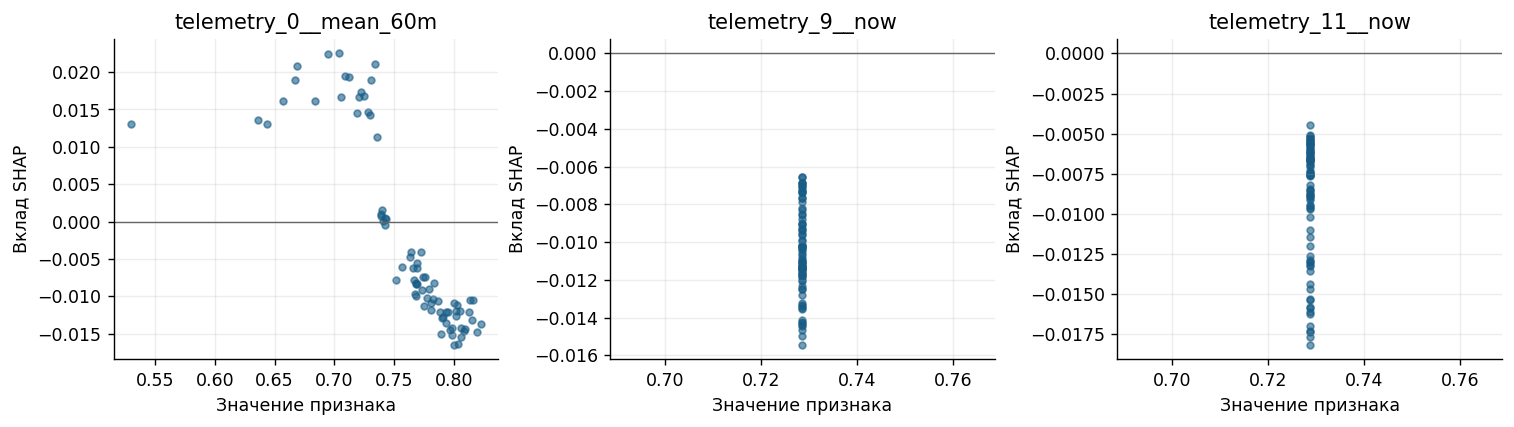

,Обучение до октября,Октябрь в обучении,Тест
telemetry_9,3453,1,2
telemetry_10,3485,1,2
telemetry_11,3418,1,2


In [11]:
best_model = fitted[winner]
x_explain = test_minute_features.loc[y_test.index, winner_cols]
feature_groups = {}
for column in x_explain:
    feature_groups.setdefault(column.split("__")[0], []).append(column)

# Сдвигаю признаки канала вместе, чтобы сохранить связи между ними.
rng = np.random.default_rng(SEED)
offsets = rng.integers(12, len(x_explain) - 12, size=20)
base_mae = mean_absolute_error(y_test, pred_at_lab[winner])
importance = []
with threadpool_limits(limits=1):
    for channel, columns in feature_groups.items():
        shuffled = x_explain.copy()
        scores = []
        for offset in offsets:
            shuffled.loc[:, columns] = np.roll(x_explain[columns].to_numpy(), offset, axis=0)
            scores.append(mean_absolute_error(y_test, best_model.predict(shuffled)) - base_mae)
        importance.append({
            "Канал": channel, "Прирост MAE": np.mean(scores),
            "Ст. откл. по сдвигам": np.std(scores, ddof=1),
        })
permutation = pd.DataFrame(importance).set_index("Канал").sort_values("Прирост MAE", ascending=False)
display(permutation)

positions = np.linspace(0, len(x_explain) - 1, 80, dtype=int)
shap_x = x_explain.iloc[positions]
preprocess, estimator = best_model.steps[0][1], best_model.steps[-1][1]
filled_shap_x = preprocess.transform(shap_x)
with threadpool_limits(limits=1):
    if winner == "CatBoost":
        from catboost import Pool

        # Последняя колонка CatBoost — базовый прогноз.
        shap_values = estimator.get_feature_importance(
            Pool(filled_shap_x), type="ShapValues", thread_count=1
        )[:, :-1]
    elif winner == "Случайный лес":
        import shap

        explainer = shap.TreeExplainer(estimator, feature_perturbation="tree_path_dependent")
        shap_values = explainer.shap_values(filled_shap_x)
    else:
        # Для линейной модели с независимым фоном SHAP равен beta * (x - E[X]).
        background = preprocess.transform(x_train[winner_cols]).mean(axis=0)
        shap_values = (filled_shap_x - background) * estimator.coef_

shap_frame = pd.DataFrame(shap_values, index=shap_x.index, columns=shap_x.columns)
shap_rank = shap_frame.abs().mean().sort_values(ascending=False)
display(shap_rank.head(10).rename("Среднее |SHAP|").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), layout="constrained")
permutation["Прирост MAE"].head(8).sort_values().plot.barh(ax=axes[0], color="#185c86")
axes[0].set(title="Перестановочная важность каналов", xlabel="Среднее изменение MAE", ylabel="")
axes[0].axvline(0, color="#666666", lw=0.8)
shap_rank.head(8).sort_values().plot.barh(ax=axes[1], color="#185c86")
axes[1].set(title="Вклад отдельных признаков", xlabel="Среднее |SHAP|", ylabel="")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), layout="constrained")
for ax, column in zip(axes, shap_rank.head(3).index):
    ax.scatter(shap_x[column], shap_frame[column], s=15, alpha=0.60, color="#185c86")
    ax.axhline(0, color="#666666", lw=0.8)
    ax.set(title=column, xlabel="Значение признака", ylabel="Вклад SHAP")
plt.show()

print("Уникальные минутные показания в каналах 9–11:")
compare_channels = ["telemetry_9", "telemetry_10", "telemetry_11"]
display(pd.DataFrame({
    "Обучение до октября": telemetry_train.loc[:"2019-09-30", compare_channels].nunique(),
    "Октябрь в обучении": telemetry_train.loc["2019-10-01":, compare_channels].nunique(),
    "Тест": telemetry_test[compare_channels].nunique(),
}))

**Вывод по оценке.** На 318 пробах лес получил MAE 0,0627, RMSE 0,0779, MAPE 35,05% и WAPE 29,91%. MAE примерно на 18% ниже ошибки медианы. Короткая история подняла точность направления с 53,2% до 55,9%.

CatBoost дал самый низкий MAE (0,0622), МНК лучше угадывает направление (57,9%). AIC предпочёл МНК с динамикой, BIC — простую версию. Пакетный прогноз на 39 747 минутах занял около 2 мс у МНК, 19 мс у CatBoost и 84 мс у леса.

Лес в среднем завышает прогноз на 0,0132. На Q–Q графике самые большие остатки уходят от прямой. На ACF видно, что соседние ошибки связаны. Разброс остатков растёт с 0,063 до 0,090 между крайними группами прогноза.

## 5. Интерпретация результата

При сдвиге признаков `telemetry_0` MAE вырос на 0,0048. У его часового среднего самый большой вклад по SHAP. Высокие значения обычно снижают прогноз. Возможно, здесь сказывается инерция печи: важен режим за последний час. Какую величину измеряет этот канал, из данных не видно.

У каналов 9–11 есть вклад по SHAP, а перестановка почти ничего не меняет. Показания этих каналов на тесте почти постоянны. Такое плато может смещать общий уровень прогноза, а от пробы к пробе показания почти одинаковы.

**Вывод по работе.** Датчик даёт оценку между пробами, но сглаживает резкие пики и угадывает направление примерно в 56% случаев. Для оператора это дополнительный ориентир при контроле процесса.